Cross-Validation Results (5-Fold)
CV Accuracy Scores: [0.695 0.665 0.675 0.67  0.685]
Mean CV Accuracy:   0.6780 (+/- 0.0108)

Performance metrics
Accuracy:  0.6640
Precision: 0.6589
Recall:    0.6800
F1-score:  0.6693

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.65      0.66       125
           1       0.66      0.68      0.67       125

    accuracy                           0.66       250
   macro avg       0.66      0.66      0.66       250
weighted avg       0.66      0.66      0.66       250

Confusion Matrix:
 [[81 44]
 [40 85]]


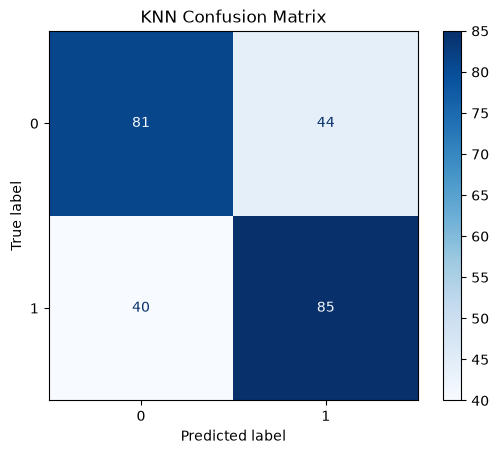

ROC-AUC Score: 0.7068



In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import dump, load
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    classification_report,
)

current_dir = Path.cwd()
data_dir = current_dir.resolve().parents[1] / "data"
artifact_dir = current_dir.resolve().parents[1] / "artifacts"

def train_KNN(name, train_set):
    filename = f"{train_set}.csv"
    model_filename =  f"{name}.joblib"

    train_set = pd.read_csv(data_dir / filename)
    # Step 1.1: Seperate the last column from both data sets since it is the target

    x_train = train_set.drop(columns=["IsCanceled"])
    y_train = train_set["IsCanceled"]

    # Step 2: Run model with data
    knn = KNeighborsClassifier(n_neighbors=3)

    knn.fit(x_train, y_train)
    show_cross_validation(knn, x_train, y_train, 5)

    dump(knn, artifact_dir / model_filename)

def test_KNN(name, test_set):
    test_filename = f"{test_set}.csv"
    model_filename =  f"{name}.joblib"
    test_set = pd.read_csv(data_dir / test_filename)
    knn = load(artifact_dir / model_filename)

    X_test = test_set.drop(columns=["IsCanceled"])
    y_test = test_set["IsCanceled"]

    y_pred = knn.predict(X_test)

    # Get prediction probabilities (required for ROC-AUC)
    y_prob = knn.predict_proba(X_test)[:, 1]

    show_test_results(y_test, y_pred, y_prob)

def show_test_results(y_test, y_pred, y_prob):
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="binary")
    rec = recall_score(y_test, y_pred, average="binary")
    f1 = f1_score(y_test, y_pred, average="binary")

    # Step 3: Evaluate the model's performance
    print("Performance metrics")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-score:  {f1:.4f}\n")

    # Detailed text report for all classes
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # ROC-AUC
    try:
        roc_auc = roc_auc_score(y_test, y_prob)
        print(f"ROC-AUC Score: {roc_auc:.4f}\n")
    except Exception as e:
        print(
            "ROC-AUC skipped: ", e
        )

    # Confusion matrix plot
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix:\n", cm)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap=plt.cm.Blues)
    plt.title("KNN Confusion Matrix")
    plt.show()

def show_cross_validation(knn, X_train, y_train, cv):
    cv_scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy")

    print(f"Cross-Validation Results ({cv}-Fold)")
    print(f"CV Accuracy Scores: {cv_scores}")
    print(
        f"Mean CV Accuracy:   {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})\n"
    )
        

train_KNN("A", "hotel_knn_train")
test_KNN("A", "hotel_knn_test")





